# Sleep-EDFx: literatura, variables nuevas y ajuste de CatBoost

Campaña reproducible sobre los **62 sujetos de desarrollo**, con cinco folds fijos y los 16 sujetos de test reservados. Métrica primaria: **F1 macro promedio entre folds**. Secundarias: accuracy, kappa y F1 por estadio. El ganador se selecciona con las métricas de desarrollo; su confirmación científica queda para el test final.

Este notebook revisa los resultados guardados. `RUN_TRAINING = True` inicia explícitamente la campaña y reutiliza checkpoints compatibles. No carga modelos externos preentrenados.


In [1]:
from pathlib import Path
import os
import json
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sleep_staging.config import project_root, CLASSES, read_yaml
from sleep_staging.research import SPECS, TUNING_CANDIDATES, run_research_campaign
from sleep_staging.evaluation import evaluate

ROOT = project_root()
TUNING_CANDIDATES[:] = read_yaml(ROOT / "configs/research/catboost-moderate.yaml")["candidates"]
OUTPUT = ROOT / "var/research/sc-w30-v2"
SOURCE_ROOT = Path(os.environ.get("SLEEP_RESEARCH_DATA_ROOT", str(ROOT)))
RUN_TRAINING = False
PRIMARY_METRIC = "f1_macro"
SECONDARY_METRICS = ["accuracy", "kappa"]
RANDOM_STATE = 42
print("Python:", platform.python_version())
display(pd.Series({p: version(p) for p in ["numpy", "scipy", "pandas", "scikit-learn", "catboost", "lightgbm", "mlflow"]}, name="version"))


/Users/adrianalarcon/.paradev/projects/maia_proyecto/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.0


numpy            2.5.4
scipy           1.18.1
pandas           2.3.3
scikit-learn     1.9.1
catboost        1.2.10
lightgbm         4.7.0
mlflow          3.17.1
Name: version, dtype: object

## Literatura y decisiones

- [Vallat y Walker, YASA (2021)](https://pmc.ncbi.nlm.nih.gov/articles/PMC8516415/): probar descriptores no lineales, canales complementarios y suavizado de variables entre segmentos. Se adapta el contexto; no se reproduce el modelo preentrenado.
- [Supratak et al., DeepSleepNet (2017)](https://arxiv.org/abs/1703.04046): justifica estudiar dependencias entre épocas. La CNN compacta del piloto no constituye una reproducción de esta arquitectura.
- [Mari et al., fusión multicanal (2026)](https://www.mdpi.com/1424-8220/26/19/6011): motiva separar las contribuciones de canales y contexto mediante ablaciones. Su protocolo de vigilia difiere del presente.
- [CatBoost, documentación oficial](https://catboost.ai/docs/en/references/training-parameters/): profundidad, regularización, balanceo y detención temprana se exploran con validación interna por sujeto.

La revisión y los límites de cada comparación se documentan en `docs/literature-model-improvements.md`. Las cifras de artículos con otros sujetos, recortes, canales o particiones no se comparan directamente con este leaderboard.


## Protocolo, datos y ejecución

El pipeline mantiene el recorte supervisado de vigilia de 30 minutos del informe para aislar el efecto de las nuevas variables. Ese recorte continúa siendo dependiente de anotaciones. La extracción selecciona sujetos de desarrollo antes de abrir EDFs, comprueba sus SHA-256 y procesa un registro a la vez. El EMG Cassette conserva su envolvente nativa a 1 Hz.

Se usan los cinco folds agrupados de `sc_subjects_v1.csv`; un KFold aleatorio por época causaría fuga entre sujetos/noches y por ello no se utiliza. La modalidad temporal es retrospectiva: incluye segmentos vecinos futuros y normalización por noche, con reinicio de ventanas en registros y huecos temporales.


In [2]:
if RUN_TRAINING:
    campaign = run_research_campaign(
        SOURCE_ROOT, ROOT / "configs/splits/sc_subjects_v1.csv", OUTPUT
    )
else:
    if not (OUTPUT / "campaign.json").exists():
        raise FileNotFoundError("Ejecutar scripts/run_research.py con --source-root antes de revisar resultados.")
    campaign = json.loads((OUTPUT / "campaign.json").read_text())
board = pd.read_csv(OUTPUT / "leaderboard.csv").sort_values("f1_macro", ascending=False).reset_index(drop=True)
raw = pd.read_parquet(campaign["dataset"])
frame = raw[raw.task_5.notna()].copy()
splits = pd.read_csv(ROOT / "configs/splits/sc_subjects_v1.csv")
reserved = set(splits.loc[splits.partition.eq("test"), "subject_id"])
assert not set(frame.subject_id) & reserved
assert frame.groupby("subject_id").fold.nunique().max() == 1
assert set(frame.fold) == set(range(5))
print("Sujetos:", frame.subject_id.nunique(), "| Registros:", frame.recording_id.nunique(), "| Épocas:", len(frame))
print("Test evaluado:", campaign["test_evaluated"])
display(frame.groupby("fold").agg(sujetos=("subject_id", "nunique"), registros=("recording_id", "nunique"), epocas=("epoch_id", "count")))
display(frame.task_5.value_counts().reindex(CLASSES["task_5"]).rename("epocas").to_frame())


Sujetos: 62 | Registros: 122 | Épocas: 152052
Test evaluado: False


,sujetos,registros,epocas
fold,,,
0,13,25,29788
1,13,26,33150
2,12,24,33483
3,12,23,28353
4,12,24,27278


,epocas
task_5,
W,48777
N1,16603
N2,54955
N3,10656
REM,21061


## Línea base y registro de ingeniería de variables

Todas las comparaciones usan los mismos segmentos. Se recalculan RF y CatBoost con las 25 variables originales de Fpz-Cz. Las características se extraen vectorizadamente y se almacenan como float32; no se exige igualdad bit a bit con artefactos históricos de otra extracción. La referencia válida para las mejoras es la línea base recalculada en esta campaña.


In [3]:
feature_log = pd.DataFrame([
    ("eeg_v1", "25 variables originales de Fpz-Cz", "Referencia comparable"),
    ("eeg_extended", "IQR, MAD, longitud de señal, entropía de permutación, Petrosian, log-potencias/ratios, borde espectral y RMS por subventanas", "Información adicional en el mismo canal"),
    ("multichannel_v1", "Variables originales de Fpz-Cz, Pz-Oz, EOG y EMG nativo", "Aislar el aporte de canales"),
    ("multichannel_extended", "Canales adicionales y descriptores ampliados", "Aislar el aporte de variables nuevas"),
    ("context_offline", "Variables ampliadas más medias previas de 2 min y centradas de 7,5 min; normalización robusta por noche", "Contexto temporal retrospectivo sin etiquetas como variables")
], columns=["bloque", "variables", "hipotesis"])
display(feature_log)
display(board[board.name.isin(["rf_eeg_v1", "catboost_eeg_v1"])][["name", "features", "f1_macro", "f1_std", "accuracy", "kappa"]])


,bloque,variables,hipotesis
0,eeg_v1,25 variables originales de Fpz-Cz,Referencia comparable
1,eeg_extended,"IQR, MAD, longitud de señal, entropía de permu...",Información adicional en el mismo canal
2,multichannel_v1,"Variables originales de Fpz-Cz, Pz-Oz, EOG y E...",Aislar el aporte de canales
3,multichannel_extended,Canales adicionales y descriptores ampliados,Aislar el aporte de variables nuevas
4,context_offline,Variables ampliadas más medias previas de 2 mi...,Contexto temporal retrospectivo sin etiquetas ...


,name,features,f1_macro,f1_std,accuracy,kappa
5,rf_eeg_v1,25,0.654384,0.021237,0.712594,0.611989
7,catboost_eeg_v1,25,0.643802,0.028695,0.687252,0.587691


## CatBoost y ajuste interno de hiperparámetros

Se comparan primero configuraciones fijas para identificar el aporte de cada bloque. El experimento ajustado usa cinco folds externos y, dentro de cada entrenamiento externo, un holdout del 20 % de sus sujetos. Los tres candidatos comparten ese holdout interno. El número de árboles se decide con F1 macro interno sin ponderar y paciencia de 50 iteraciones; después se reentrena en todo el entrenamiento externo antes de predecir su fold. La validación externa no controla early stopping.

Este procedimiento usa holdout interno, no cinco folds internos. La comparación entre múltiples familias/variables sigue siendo exploratoria y requiere confirmación con el test reservado.


In [4]:
tuned_rows = board[board.name.eq("catboost_tuned_context")]
if not tuned_rows.empty:
    run_dir = Path(tuned_rows.iloc[0].run_dir)
    actual_grid = json.loads((run_dir / "summary.json").read_text())["identity"]["tuning"]
    display(pd.DataFrame(actual_grid))
    tuning_audit = []
    for f in sorted(run_dir.glob("fold-*.json")):
        s = json.loads(f.read_text())
        a = s["training"]
        assert not set(a["training_subjects"]) & set(a["validation_subjects"])
        tuning_audit.append({"fold_externo": s["fold"], **a["chosen_params"], "f1_externo": s["metrics"]["f1_macro"]})
    display(pd.DataFrame(tuning_audit))


,iterations,depth,learning_rate,l2_leaf_reg,auto_class_weights,rsm,border_count
0,300,4,0.08,3,Balanced,0.6,64
1,400,5,0.06,5,SqrtBalanced,0.6,64
2,500,6,0.05,9,None,0.6,64


,fold_externo,iterations,depth,learning_rate,l2_leaf_reg,auto_class_weights,rsm,border_count,f1_externo
0,0,240,5,0.06,5,SqrtBalanced,0.6,64,0.746656
1,1,332,5,0.06,5,SqrtBalanced,0.6,64,0.791012
2,2,60,5,0.06,5,SqrtBalanced,0.6,64,0.762746
3,3,318,5,0.06,5,SqrtBalanced,0.6,64,0.800958
4,4,446,6,0.05,9,None,0.6,64,0.775414


## Leaderboard y ganador de cada iteración

F1 macro, accuracy y kappa son promedios de los cinco folds. La desviación es entre folds. N1/REM se resumen con predicciones OOF agrupadas; su agregación es distinta. El tiempo es coste de ejecución local y puede variar con la carga de la máquina.


,name,features,f1_macro,f1_std,accuracy,kappa,n1_f1_oof,rem_f1_oof,elapsed_seconds
0,lightgbm_context_offline,435,0.7822,0.0161,0.8167,0.7539,0.5234,0.8528,409.2074
1,catboost_tuned_context,435,0.7754,0.0194,0.8207,0.7555,0.4766,0.8424,2116.5985
2,catboost_context_offline,435,0.7690,0.0198,0.7992,0.7332,0.5085,0.8483,574.8955
3,catboost_multichannel_extended,145,0.7314,0.0326,0.7636,0.6876,0.4626,0.7536,193.6704
4,catboost_multichannel_v1,88,0.7270,0.0318,0.7602,0.6824,0.4542,0.7471,132.4448
5,rf_eeg_v1,25,0.6544,0.0212,0.7126,0.6120,0.3106,0.5566,98.9973
6,catboost_eeg_extended,42,0.6493,0.0282,0.6924,0.5947,0.3540,0.5568,73.4490
7,catboost_eeg_v1,25,0.6438,0.0287,0.6873,0.5877,0.3464,0.5535,55.7611


Iteración rf_eeg_v1: F1=0.6544; accuracy=0.7126; kappa=0.6120; Winner model: rf_eeg_v1
Iteración catboost_eeg_v1: F1=0.6438; accuracy=0.6873; kappa=0.5877; Winner model: rf_eeg_v1
Iteración catboost_eeg_extended: F1=0.6493; accuracy=0.6924; kappa=0.5947; Winner model: rf_eeg_v1
Iteración catboost_multichannel_v1: F1=0.7270; accuracy=0.7602; kappa=0.6824; Winner model: catboost_multichannel_v1
Iteración catboost_multichannel_extended: F1=0.7314; accuracy=0.7636; kappa=0.6876; Winner model: catboost_multichannel_extended
Iteración catboost_context_offline: F1=0.7690; accuracy=0.7992; kappa=0.7332; Winner model: catboost_context_offline
Iteración lightgbm_context_offline: F1=0.7822; accuracy=0.8167; kappa=0.7539; Winner model: lightgbm_context_offline
Iteración catboost_tuned_context: F1=0.7754; accuracy=0.8207; kappa=0.7555; Winner model: lightgbm_context_offline


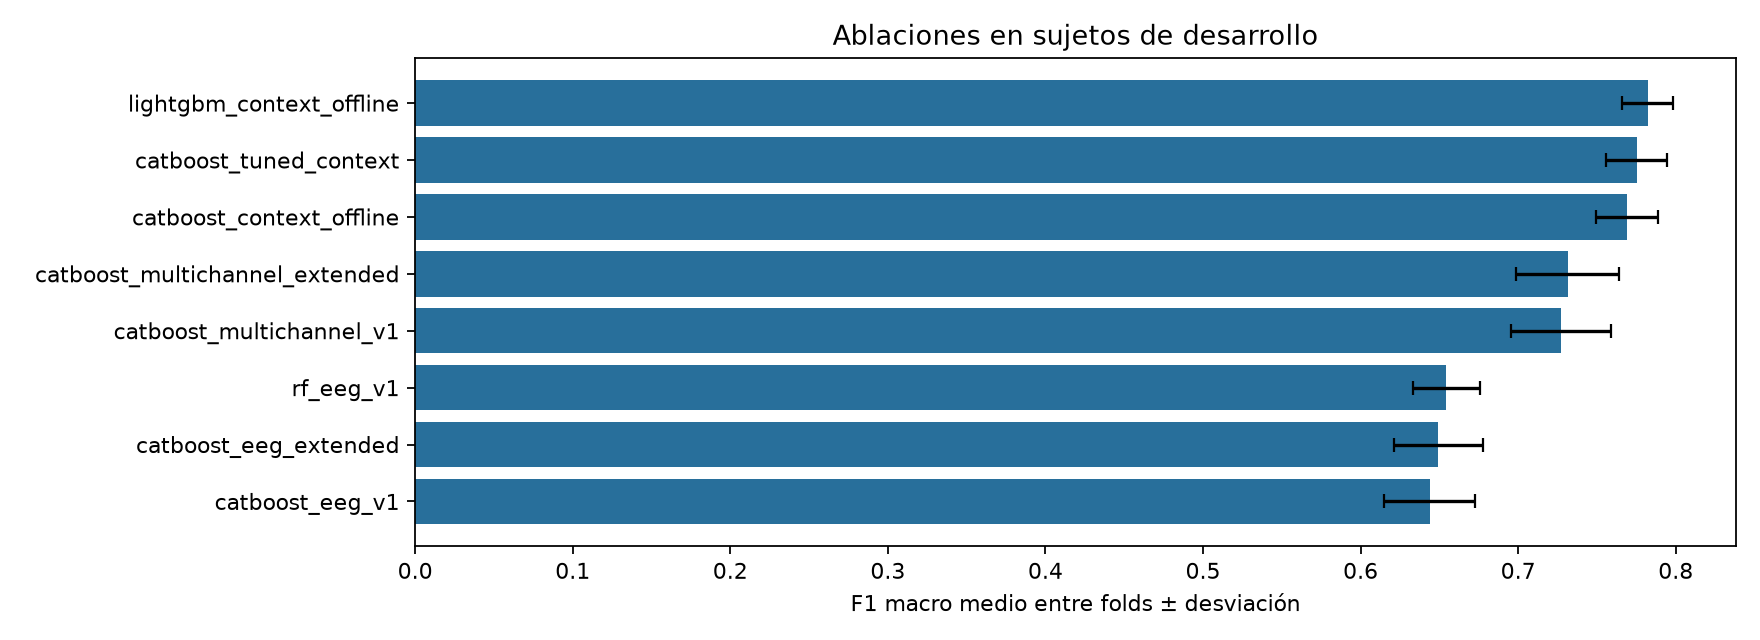

In [5]:
columns = ["name", "features", "f1_macro", "f1_std", "accuracy", "kappa", "n1_f1_oof", "rem_f1_oof", "elapsed_seconds"]
display(board[columns].round(4))
iteration = []
for spec in SPECS:
    row = board[board.name.eq(spec.name)]
    if not row.empty:
        iteration.append(row.iloc[0])
        current = max(iteration, key=lambda x: x.f1_macro)
        print(f"Iteración {spec.name}: F1={row.iloc[0].f1_macro:.4f}; accuracy={row.iloc[0].accuracy:.4f}; kappa={row.iloc[0].kappa:.4f}; Winner model: {current['name']}")
fig, ax = plt.subplots(figsize=(11, 4))
ordered = board.sort_values("f1_macro")
ax.barh(ordered.name, ordered.f1_macro, xerr=ordered.f1_std, color="#286F9B", capsize=3)
ax.set(xlabel="F1 macro medio entre folds ± desviación", title="Ablaciones en sujetos de desarrollo")
fig.tight_layout()
fig.savefig(OUTPUT / "model-comparison.png", dpi=160)
display(Image(filename=str(OUTPUT / "model-comparison.png")))
plt.close(fig)


## Errores por estadio, sujeto e incertidumbre

El bootstrap emparejado remuestrea sujetos completos con todas sus noches. El intervalo representa la diferencia de F1 macro OOF agrupado frente a RF, condicionado a los modelos OOF ya ajustados; no sustituye la evaluación final ni incorpora toda la variabilidad de reentrenamiento.


,precision,recall,f1-score,support
W,0.948361,0.889702,0.918096,48777.0
N1,0.449704,0.626031,0.523416,16603.0
N2,0.888118,0.777982,0.829410,54955.0
N3,0.706116,0.900338,0.791486,10656.0
REM,0.845003,0.860690,0.852774,21061.0


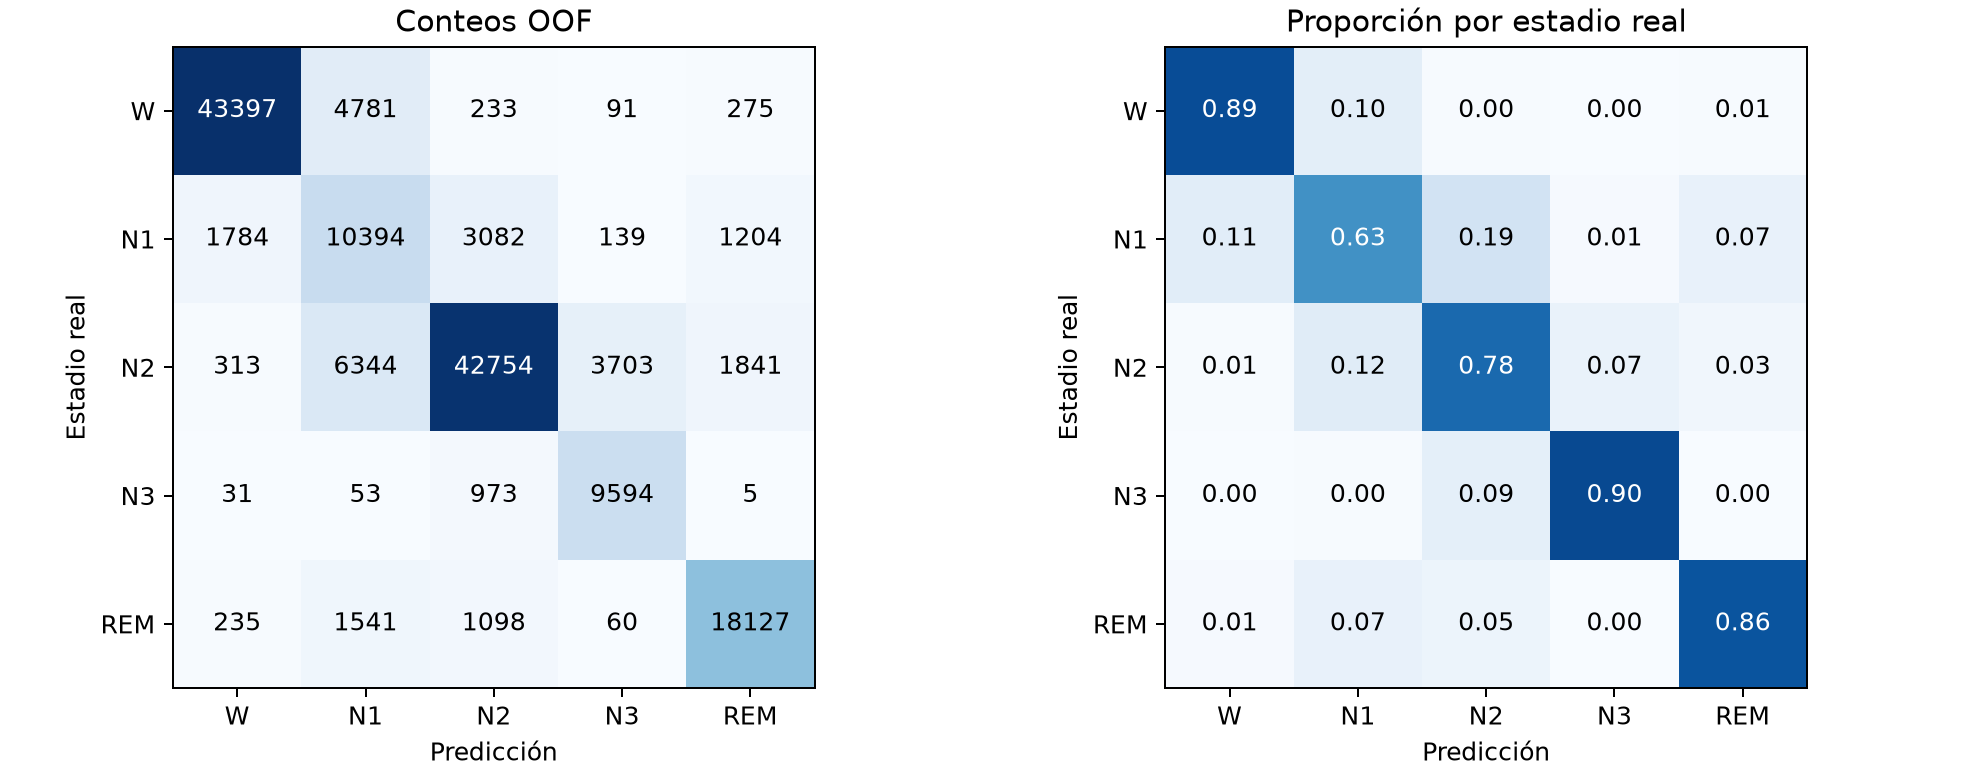

f1_macro                      accuracy            \
                              mean    median       std      mean    median   
model                                                                        
lightgbm_context_offline  0.736399  0.750305  0.078936  0.814536  0.817796   
rf_eeg_v1                 0.596132  0.614008  0.103143  0.708497  0.722814   

                                       kappa                      
                               std      mean    median       std  
model                                                             
lightgbm_context_offline  0.056971  0.741689  0.752037  0.077500  
rf_eeg_v1                 0.091360  0.592422  0.620215  0.122354

metric                        pooled_oof_macro_f1_difference
reference                                          rf_eeg_v1
delta                                               0.128235
ci95               [0.11657087588670895, 0.1410664133659993]
subjects                                                  62
repeats                                                 2000
scope        conditional_on_fitted_oof_models_not_final_test
dtype: object

In [6]:
best = board.iloc[0]
reference = board.loc[board.name.eq("rf_eeg_v1")].iloc[0]
oof = pd.read_parquet(Path(best.run_dir) / "oof.parquet")
base_oof = pd.read_parquet(Path(reference.run_dir) / "oof.parquet")
assert len(oof) == frame.shape[0] and not oof.epoch_id.duplicated().any()
metrics = evaluate(oof.y_true.to_numpy(), oof.y_pred.to_numpy(), CLASSES["task_5"])
display(pd.DataFrame(metrics["report"]).T.reindex(CLASSES["task_5"])[["precision", "recall", "f1-score", "support"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
for ax, key, title in zip(axes, ["confusion", "confusion_normalized"], ["Conteos OOF", "Proporción por estadio real"]):
    matrix = np.asarray(metrics[key])
    maximum = 1.0 if key.endswith("normalized") else float(matrix.max())
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=maximum)
    ax.set_xticks(range(5), CLASSES["task_5"])
    ax.set_yticks(range(5), CLASSES["task_5"])
    ax.set(xlabel="Predicción", ylabel="Estadio real", title=title)
    for (i, j), value in np.ndenumerate(matrix):
        label = f"{value:.2f}" if key.endswith("normalized") else str(int(value))
        ax.text(j, i, label, ha="center", va="center", color="white" if value > maximum * 0.5 else "black")
fig.savefig(OUTPUT / "candidate-confusion.png", dpi=180)
display(Image(filename=str(OUTPUT / "candidate-confusion.png")))
plt.close(fig)
subject_rows = []
for name, data in [(reference["name"], base_oof), (best["name"], oof)]:
    for subject, group in data.groupby("subject_id", sort=True):
        result = evaluate(group.y_true.to_numpy(), group.y_pred.to_numpy(), CLASSES["task_5"])
        subject_rows.append({"model": name, "subject_id": subject, "f1_macro": result["f1_macro"], "accuracy": result["accuracy"], "kappa": result["kappa"]})
subject_metrics = pd.DataFrame(subject_rows)
subject_metrics.to_csv(OUTPUT / "subject-metrics.csv", index=False)
display(subject_metrics.groupby("model")[["f1_macro", "accuracy", "kappa"]].agg(["mean", "median", "std"]))
display(pd.Series(campaign.get("paired_bootstrap") or {}))


## Variables que utiliza el candidato

Importancia interna del modelo reentrenado en desarrollo. Es descriptiva y puede repartirse entre variables correlacionadas; no demuestra una relación causal ni sustituye las ablaciones.


Importancia interna: número de divisiones


,feature,importance
38,eeg_fpz_cz__eeg__log_ratio_sigma_beta,239
130,emg__emg_envelope__median,230
79,eeg_pz_oz__eeg__log_ratio_theta_alpha,212
382,eog__eog__kurtosis__context_center15,204
328,eeg_fpz_cz__eeg__log_ratio_sigma_beta__context...,183
313,eeg_fpz_cz__eeg__relative_theta__context_center15,181
364,eeg_pz_oz__eeg__relative_beta__context_center15,176
131,emg__emg_envelope__q90,172
411,eog__eog__log_ratio_theta_alpha__context_center15,171
80,eeg_pz_oz__eeg__log_ratio_sigma_beta,167


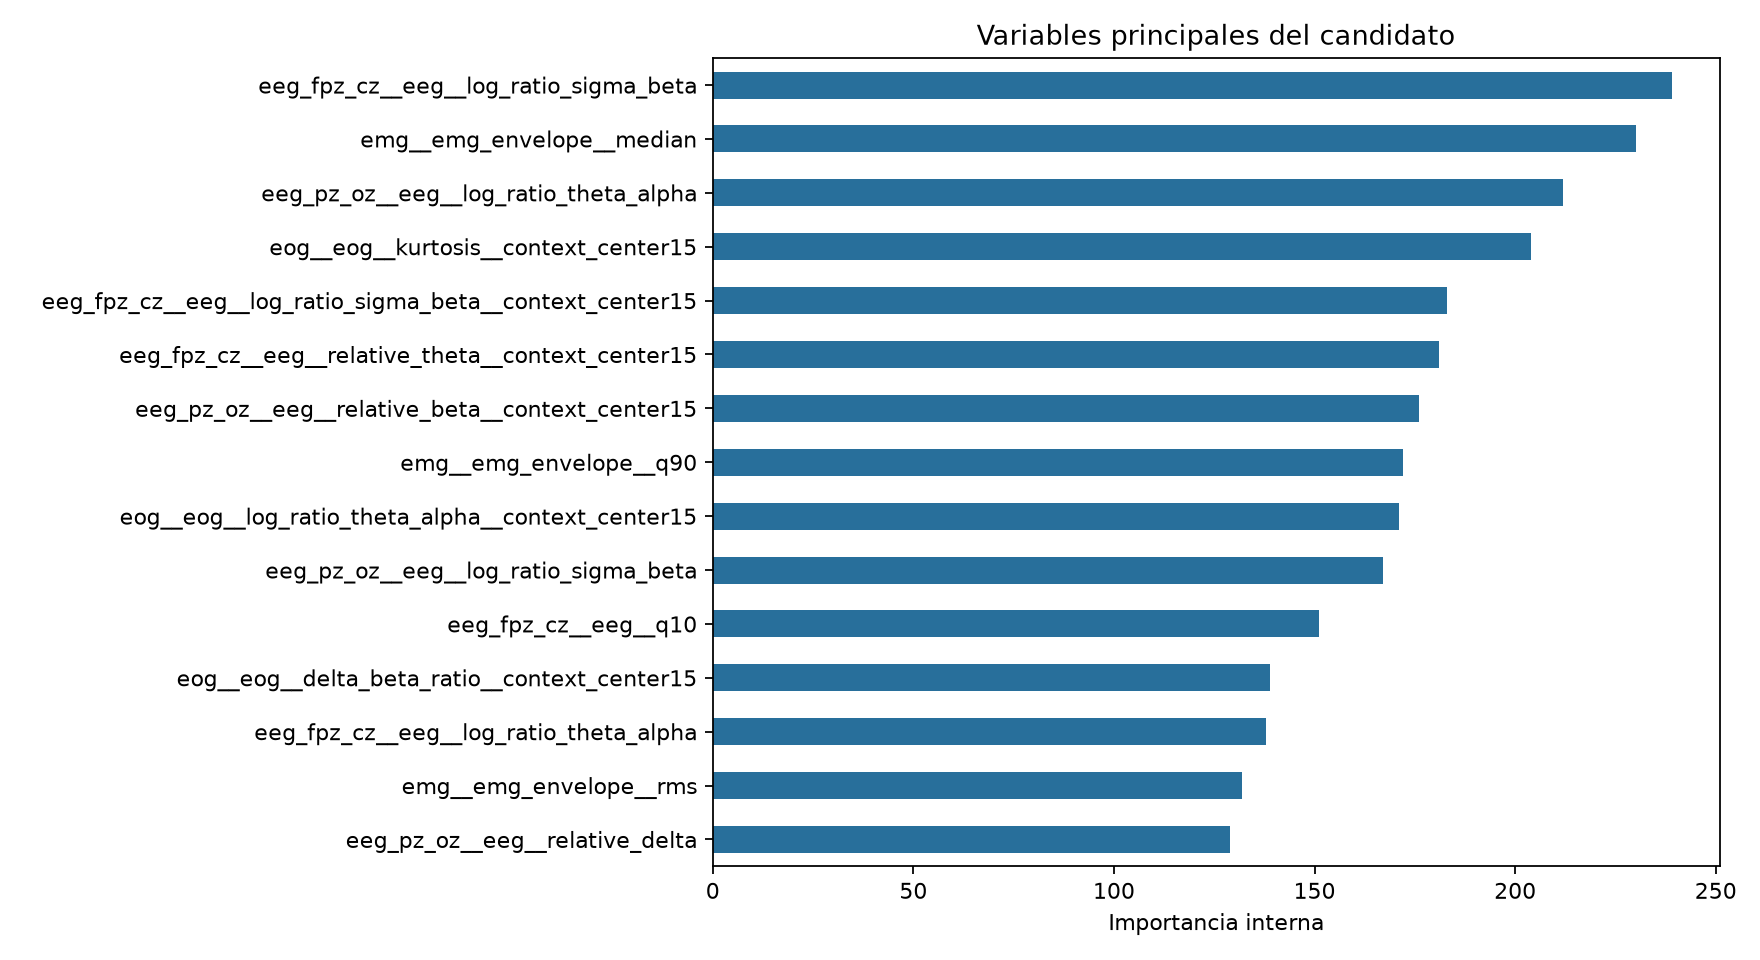

In [7]:
import joblib
bundle = joblib.load(OUTPUT / "candidate.joblib")
estimator = bundle["model"]
if hasattr(estimator, "named_steps"):
    estimator = estimator.named_steps["classifier"]
importance_kind = {"lgbm": "número de divisiones", "catboost": "cambio de valores de predicción", "rf": "reducción de impureza"}[bundle["spec"]["family"]]
print("Importancia interna:", importance_kind)
importance = pd.DataFrame({"feature": bundle["feature_columns"], "importance": estimator.feature_importances_}).sort_values("importance", ascending=False)
importance.to_csv(OUTPUT / "feature-importance.csv", index=False)
display(importance.head(20))
fig, ax = plt.subplots(figsize=(11, 6))
importance.head(15).sort_values("importance").plot.barh(x="feature", y="importance", ax=ax, legend=False, color="#286F9B")
ax.set(title="Variables principales del candidato", xlabel="Importancia interna", ylabel="")
fig.tight_layout()
fig.savefig(OUTPUT / "feature-importance.png", dpi=160)
display(Image(filename=str(OUTPUT / "feature-importance.png")))
plt.close(fig)


## Prueba adicional: ensamble fijo de probabilidades OOF

Se evalúa un promedio 50/50 de LightGBM y CatBoost de configuración fija con contexto. Ambos componentes predicen cada segmento desde el mismo fold externo, sin entrenar con su sujeto. Los pesos se fijan en 0,5 y no se optimizan con etiquetas. Es una comparación exploratoria adicional; si no supera al mejor componente, se conserva el modelo individual. Esta prueba no entrena ni guarda un candidato de ensamble.


In [8]:
component_names = ["lightgbm_context_offline", "catboost_context_offline"]
components = []
for name in component_names:
    row = board.loc[board.name.eq(name)].iloc[0]
    table = pd.read_parquet(Path(row.run_dir) / "oof.parquet").sort_values("epoch_id").reset_index(drop=True)
    components.append(table)
a, b = components
assert a[["epoch_id", "subject_id", "fold", "y_true"]].equals(b[["epoch_id", "subject_id", "fold", "y_true"]])
classes = CLASSES["task_5"]
prob_columns = ["prob_" + c for c in classes]
probabilities = 0.5 * a[prob_columns].to_numpy() + 0.5 * b[prob_columns].to_numpy()
ensemble_prediction = np.asarray(classes)[probabilities.argmax(axis=1)]
ensemble_folds = []
for fold in range(5):
    mask = a.fold.eq(fold)
    m = evaluate(a.loc[mask, "y_true"].to_numpy(), ensemble_prediction[mask], classes)
    ensemble_folds.append({"fold": fold, "f1_macro": m["f1_macro"], "accuracy": m["accuracy"], "kappa": m["kappa"]})
ensemble_scores = pd.DataFrame(ensemble_folds)
display(ensemble_scores)
ensemble_summary = {"name": "soft_vote_fixed_50_50", "f1_macro": ensemble_scores.f1_macro.mean(), "f1_std": ensemble_scores.f1_macro.std(ddof=0), "accuracy": ensemble_scores.accuracy.mean(), "kappa": ensemble_scores.kappa.mean()}
display(pd.Series(ensemble_summary))
comparison = board.loc[board.name.isin(component_names), ["name", "f1_macro", "f1_std", "accuracy", "kappa"]]
comparison = pd.concat([comparison, pd.DataFrame([ensemble_summary])], ignore_index=True).sort_values("f1_macro", ascending=False)
print("Winner model (componentes y ensamble fijo):", comparison.iloc[0]["name"])


,fold,f1_macro,accuracy,kappa
0,0,0.749331,0.781892,0.708298
1,1,0.782431,0.813243,0.752333
2,2,0.785045,0.838097,0.778538
3,3,0.801924,0.823758,0.768244
4,4,0.782917,0.807537,0.741894


name        soft_vote_fixed_50_50
f1_macro                 0.780329
f1_std                   0.017092
accuracy                 0.812905
kappa                    0.749861
dtype: object

Winner model (componentes y ensamble fijo): lightgbm_context_offline


## Cierre de la campaña

El candidato guardado está entrenado solo con desarrollo y requiere el mismo contrato de características. Su estimador no constituye todavía una aplicación autónoma para EDF nuevos. Las siguientes extensiones deben estudiar la eliminación del recorte dependiente de anotaciones, arquitecturas secuenciales con la misma cohorte y la evaluación final del modelo congelado.


Tracking: [MLflow local, experimento sleep-cassette-literature-v2](http://127.0.0.1:5002/#/experiments/1). Las ocho comparaciones, 15 ensayos internos y el ensamble están relacionados en `tracking-audit.json`. Modelo registrado: `models:/sleep_sc_task5_literature_v2@candidate`.


In [9]:
delta = float(best.f1_macro - reference.f1_macro)
print(f"Winner model: {best['name']}")
print(f"Family: {best.family}")
print(f"Primary metric: F1 macro = {best.f1_macro:.4f} +/- {best.f1_std:.4f}")
print(f"Secondary metrics: accuracy={best.accuracy:.4f}; kappa={best.kappa:.4f}")
print(f"CV detail: {best.fold_scores}")
print(f"Key features: {best.feature_view}; {int(best.features)} variables")
print(f"Mejora absoluta frente a RF recalculado: {delta:+.4f}")
print("Why it won: mayor F1 macro promedio sobre los cinco folds fijos de desarrollo.")
print("Notebook: notebooks/04_literature_catboost.ipynb")
print("Next iteration: validar sensibilidad al protocolo de vigilia y congelar el candidato antes del test final.")
print("Test final evaluado:", campaign["test_evaluated"])


Winner model: lightgbm_context_offline
Family: lgbm
Primary metric: F1 macro = 0.7822 +/- 0.0161
Secondary metrics: accuracy=0.8167; kappa=0.7539
CV detail: [0.7524048856371744, 0.7860628945506831, 0.7850210455415345, 0.8014505271560438, 0.7861489078011811]
Key features: context_offline; 435 variables
Mejora absoluta frente a RF recalculado: +0.1278
Why it won: mayor F1 macro promedio sobre los cinco folds fijos de desarrollo.
Notebook: notebooks/04_literature_catboost.ipynb
Next iteration: validar sensibilidad al protocolo de vigilia y congelar el candidato antes del test final.
Test final evaluado: False
